# Этап 1. Знакомство с данными и EDA

In [512]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('ggplot')

In [513]:
# data rating
raw_ratings = pd.read_csv('data/ratings.csv')

# Сначала проверяем, есть ли повторные оценки одной пары пользователь–книга
duplicate_counts = raw_ratings.groupby(['user_id', 'book_id']).size()
duplicate_pairs = duplicate_counts[duplicate_counts > 1]
different_rating_counts = raw_ratings.groupby(['user_id', 'book_id'])['rating'].nunique()

print('Повторяющихся пар пользователь–книга:', len(duplicate_pairs))
print('Лишних строк из-за повторов:', int(duplicate_pairs.sum() - len(duplicate_pairs)))
print('Пар с разными оценками:', int((different_rating_counts > 1).sum()))

# При создании csr_matrix повторяющиеся координаты складываются.
# Поэтому одну пару пользователь–книга оставляем с одной средней оценкой.
ratings = (
    raw_ratings
    .groupby(['user_id', 'book_id'], as_index=False)['rating']
    .mean()
)
print('Дубликатов после объединения:', ratings.duplicated(['user_id', 'book_id']).sum())

Повторяющихся пар пользователь–книга: 2209
Лишних строк из-за повторов: 2278
Пар с разными оценками: 633
Дубликатов после объединения: 0


In [514]:
# data books
books = pd.read_csv('data/books.csv')

# В ratings.csv book_id соответствует колонке id из books.csv.
# В book_tags.csv используется Goodreads ID из колонки book_id.
books = books.rename(columns={'id': 'book_id', 'book_id': 'goodreads_book_id'})

In [515]:
# data tags
tags = pd.read_csv('data/tags.csv')

In [516]:
# data book_tags
book_tags = pd.read_csv('data/book_tags.csv')

In [517]:
print('ratings:', ratings.shape)
print('books:', books.shape)
print('tags:', tags.shape)
print('book_tags:', book_tags.shape)

display(ratings.head())
display(books[['book_id', 'title', 'authors', 'average_rating', 'goodreads_book_id']].head())
display(tags.head())
display(book_tags.head())

ratings: (979478, 3)
books: (10000, 23)
tags: (34252, 2)
book_tags: (999912, 3)


,user_id,book_id,rating
0,1,1180,4.0
1,1,4893,3.0
2,1,6285,4.0
3,2,8034,4.0
4,2,8855,5.0


,book_id,title,authors,average_rating,goodreads_book_id
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4.34,2767052
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",4.44,3
2,3,"Twilight (Twilight, #1)",Stephenie Meyer,3.57,41865
3,4,To Kill a Mockingbird,Harper Lee,4.25,2657
4,5,The Great Gatsby,F. Scott Fitzgerald,3.89,4671


,tag_id,tag_name
0,0,-
1,1,--1-
2,2,--10-
3,3,--12-
4,4,--122-


,goodreads_book_id,tag_id,count
0,1,30574,167697
1,1,11305,37174
2,1,11557,34173
3,1,8717,12986
4,1,33114,12716


## 1. Распределение оценок

Средняя оценка: 3.86
Медианная оценка: 4.0


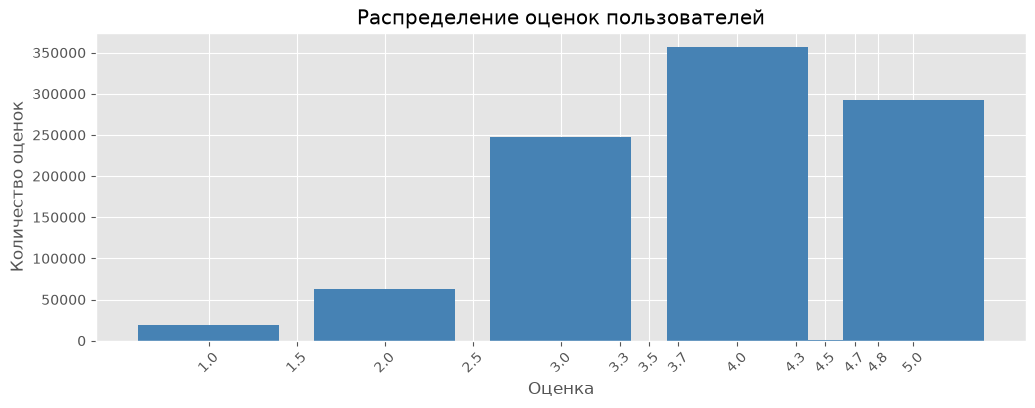

,number_of_ratings
rating,
1.000000,19513
1.500000,24
2.000000,63070
2.500000,76
3.000000,248007
3.333333,3
3.500000,194
3.666667,4
4.000000,356416


In [518]:
rating_counts = ratings['rating'].value_counts().sort_index()
print('Средняя оценка:', round(ratings['rating'].mean(), 2))
print('Медианная оценка:', ratings['rating'].median())

plt.figure(figsize=(12, 4))
plt.bar(rating_counts.index, rating_counts.values, color='steelblue')
plt.title('Распределение оценок пользователей')
plt.xlabel('Оценка')
plt.ylabel('Количество оценок')
plt.xticks(
    rating_counts.index,
    [f'{rating:.1f}' for rating in rating_counts.index],
    rotation=45
)
plt.show()

rating_counts.to_frame('number_of_ratings')

По графику видно что есть смещение оценок к 4 и 5. Если высокие оценки встречаются намного чаще низких, это важно учитывать при обучении моделей: средняя оценка книги может выглядеть завышенной.

В данных были повторные оценки одной пары пользователь–книга, поэтому перед анализом они были объединены через среднее. Из-за этого в таблице встречаются отдельные дробные значения рейтинга.

## 2. Активность пользователей

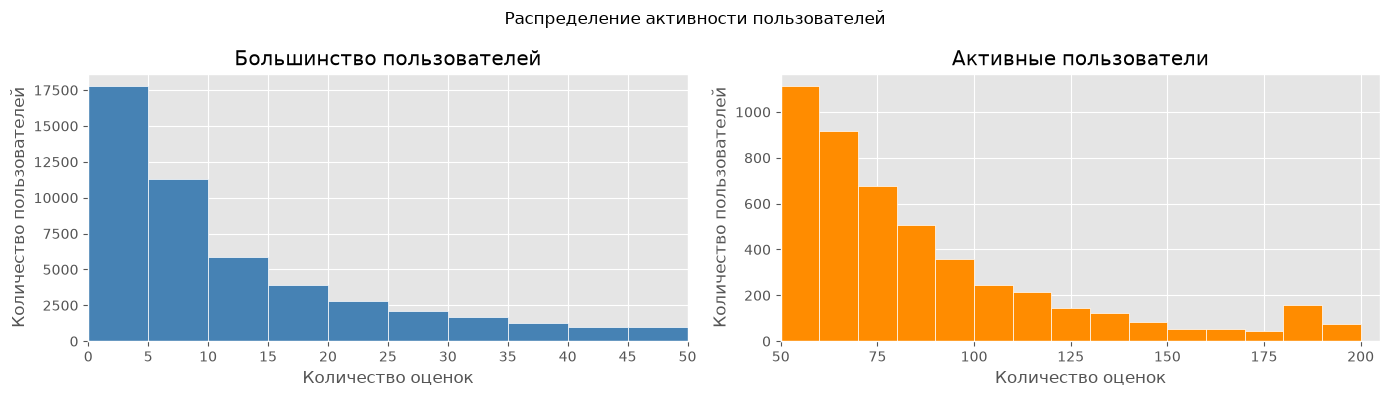

Количество пользователей: 53424
Среднее количество оценок на пользователя: 18.33
Медианное количество оценок на пользователя: 8.0
Самые активные пользователи:


user_id
12874    200
30944    200
52036    199
12381    199
28158    199
45554    197
6630     197
19729    196
9668     196
14372    196
Name: number_of_ratings, dtype: int64

Пользователи не более чем с 5 оценками: 20985
Доля таких пользователей: 39.28 %


In [519]:
ratings_per_user = ratings.groupby('user_id').size()
user_activity = ratings_per_user.value_counts().sort_index()

# По оси X — сколько оценок оставил пользователь, по оси Y — сколько таких пользователей.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Левая часть показывает основную массу пользователей.
axes[0].hist(ratings_per_user, bins=range(0, 51, 5), color='steelblue', edgecolor='white')
axes[0].set_title('Большинство пользователей')
axes[0].set_xlabel('Количество оценок')
axes[0].set_ylabel('Количество пользователей')
axes[0].set_xlim(0, 50)
axes[0].set_xticks(range(0, 51, 5))

# Правая часть показывает длинный хвост активных пользователей.
active_users = ratings_per_user[ratings_per_user > 50]
axes[1].hist(active_users, bins=range(50, 211, 10), color='darkorange', edgecolor='white')
axes[1].set_title('Активные пользователи')
axes[1].set_xlabel('Количество оценок')
axes[1].set_ylabel('Количество пользователей')
axes[1].set_xlim(50, 205)
axes[1].set_xticks(range(50, 201, 25))

# такое разбиение на 2 графика сделано для лучшей наглядности - на одном графике не читаемо на мой взгляд
fig.suptitle('Распределение активности пользователей')
plt.tight_layout()
plt.show()

print('Количество пользователей:', ratings['user_id'].nunique())
print('Среднее количество оценок на пользователя:', round(ratings_per_user.mean(), 2))
print('Медианное количество оценок на пользователя:', ratings_per_user.median())

print('Самые активные пользователи:')
display(ratings_per_user.sort_values(ascending=False).head(10).rename('number_of_ratings'))

low_activity_users = (ratings_per_user <= 5).sum()
print('Пользователи не более чем с 5 оценками:', low_activity_users)
print('Доля таких пользователей:', round(low_activity_users / len(ratings_per_user) * 100, 2), '%')

Распределение активности обычно имеет длинный хвост: небольшая группа пользователей оставляет много оценок, а у большого числа пользователей взаимодействий мало. Это подтверждают наши графики. Пользователи с одной или несколькими оценками это пример холодного старта для персональных рекомендаций.

## 3. Популярность книг

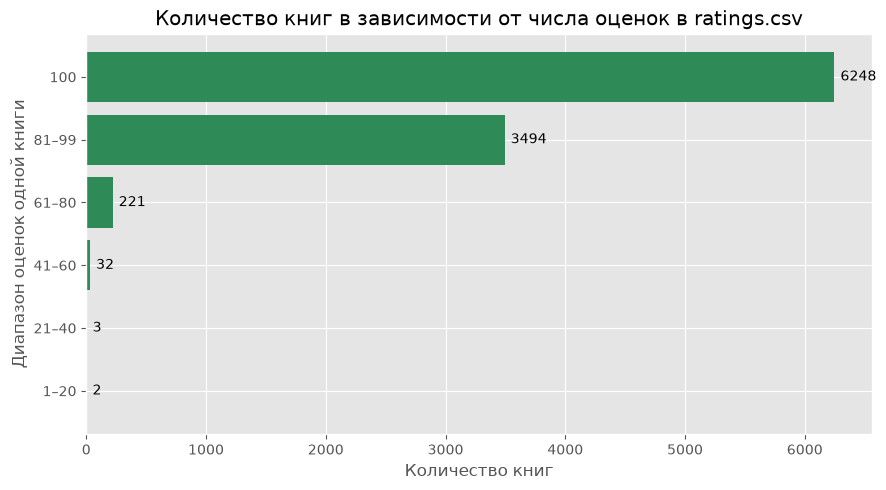

,book_id,title,number_of_ratings
0,1,"The Hunger Games (The Hunger Games, #1)",100
1,4931,At the Mountains of Madness and Other Tales of...,100
2,4927,"Red: The Heroic Rescue (The Circle, #2)",100
3,4925,Nation,100
4,4922,"Whispers Under Ground (Peter Grant, #3)",100
5,4920,Testimony,100
6,4917,"The Bourne Objective (Jason Bourne, #8)",100
7,4915,"Night Fall (John Corey, #3)",100
8,4910,Just Like Heaven (Smythe-Smith Quartet #1),100
9,4909,"N is for Noose (Kinsey Millhone, #14)",100


Книг не более чем с 20 оценками: 2
Максимальное число оценок у одной книги: 100


In [520]:
ratings_per_book = ratings.groupby('book_id').size()
book_popularity = ratings_per_book.value_counts().sort_index()

# Максимальное количество оценок в этом файле ограничено 100.
# Группируем книги по диапазонам числа оценок, чтобы увидеть это ограничение.
rating_bins = [0, 20, 40, 60, 80, 99, 100]
rating_labels = ['1–20', '21–40', '41–60', '61–80', '81–99', '100']
book_rating_groups = pd.cut(
    ratings_per_book,
    bins=rating_bins,
    labels=rating_labels,
    include_lowest=True
)
books_by_rating_group = book_rating_groups.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(books_by_rating_group.index, books_by_rating_group.values, color='seagreen')
ax.set_title('Количество книг в зависимости от числа оценок в ratings.csv')
ax.set_xlabel('Количество книг')
ax.set_ylabel('Диапазон оценок одной книги')
ax.ticklabel_format(style='plain', axis='x')

for bar, value in zip(bars, books_by_rating_group.values):
    ax.text(value + 50, bar.get_y() + bar.get_height() / 2, str(value), va='center')

plt.tight_layout()
plt.show()

popular_books = ratings_per_book.sort_values(ascending=False).head(10).rename('number_of_ratings').reset_index()
popular_books = popular_books.merge(books[['book_id', 'title']], on='book_id', how='left')
display(popular_books[['book_id', 'title', 'number_of_ratings']])

low_popularity_books = (ratings_per_book <= 20).sum()
print('Книг не более чем с 20 оценками:', low_popularity_books)
print('Максимальное число оценок у одной книги:', ratings_per_book.max())

В `ratings.csv` распределение числа оценок ограничено способом формирования выборки: 7456 книг имеют ровно 100 оценок, а книг не более чем с 20 оценками всего 2. Поэтому этот график показывает не настоящую популярность книг, а особенности сэмплирования данных. Для сравнения реальной популярности используется поле `ratings_count` из `books.csv`.

## 4. Самые частые теги

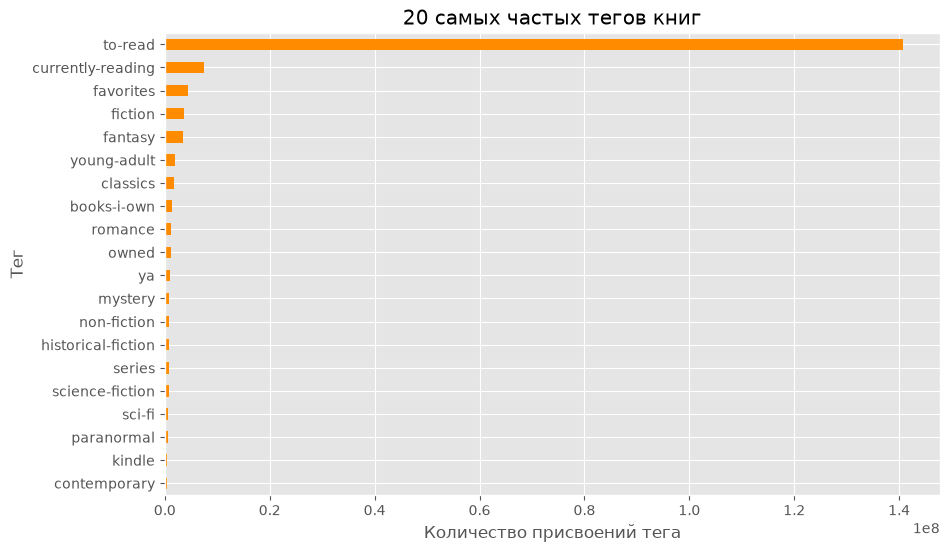

,tag_count
tag_name,
to-read,140718761
currently-reading,7507958
favorites,4503173
fiction,3688819
fantasy,3548157
young-adult,1848306
classics,1756920
books-i-own,1317235
romance,1231926


In [521]:
# В book_tags хранится tag_id, поэтому сначала добавим название тега из tags.
book_tags_with_names = book_tags.merge(tags, on='tag_id', how='left')

# count показывает, сколько раз тег был присвоен книгам пользователями.
tag_popularity = (
    book_tags_with_names.groupby('tag_name')['count']
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

plt.figure(figsize=(10, 6))
tag_popularity.sort_values().plot(kind='barh', color='darkorange')
plt.title('20 самых частых тегов книг')
plt.xlabel('Количество присвоений тега')
plt.ylabel('Тег')
plt.show()

display(tag_popularity.to_frame('tag_count'))

## 5. Разреженность матрицы пользователь–книга

In [522]:
number_of_users = ratings['user_id'].nunique()
number_of_books = books['book_id'].nunique()
number_of_ratings = len(ratings)
possible_interactions = number_of_users * number_of_books
sparsity = 1 - number_of_ratings / possible_interactions

print('Всего возможных пар пользователь–книга:', f'{possible_interactions:,}')
print('Наблюдаемых оценок:', f'{number_of_ratings:,}')
print('Разреженность матрицы:', round(sparsity * 100, 2), '%')

Всего возможных пар пользователь–книга: 534,240,000
Наблюдаемых оценок: 979,478
Разреженность матрицы: 99.82 %


## Выводы по EDA

1. В оценках заметно смещение к высоким значениям: оценки 4 и 5 встречаются чаще низких. Поэтому средняя оценка книги может выглядеть завышенной. Дробные значения появились только из-за усреднения повторных оценок одной пары пользователь–книга.
2. Активность пользователей распределена неравномерно: есть небольшая группа очень активных пользователей и много пользователей с малым числом оценок. Для последних персональные рекомендации строить сложнее.
3. В ratings.csv максимум равен 100 оценкам на книгу: 7456 книг имеют ровно 100 оценок, а книг не более чем с 20 оценками всего 2. Поэтому этот файл ограниченно показывает популярность, и для дополнительного сравнения используется ratings_count из books.csv.
4. Матрица пользователь - книга сильно разрежена (99.82 %): число возможных взаимодействий намного больше числа наблюдаемых оценок. Поэтому коллаборативные методы могут плохо работать для новых пользователей и редко оцениваемых книг.
5. Частые теги можно использовать в контентной модели: они дают дополнительное описание книги и помогают рекомендовать книги при недостатке пользовательской истории.

# Этап 2. Базовые и контентные модели

Сначала построим простой неперсонализированный бейзлайн, затем используем названия книг и теги для поиска похожих книг.

## 1. Top-N популярных книг

In [523]:
def get_popular_books(n=10, min_ratings=50):
    """Возвращает N книг с самым высоким средним рейтингом."""
    book_stats = (
        ratings.groupby('book_id')['rating']
        .agg(['mean', 'count'])
        .reset_index()
        .rename(columns={'mean': 'average_rating', 'count': 'number_of_ratings'})
    )

    popular_books = book_stats[book_stats['number_of_ratings'] >= min_ratings]
    popular_books = popular_books.sort_values(
        ['average_rating', 'number_of_ratings'],
        ascending=[False, False]
    )

    return (
        popular_books.head(n)
        .merge(books[['book_id', 'title', 'authors']], on='book_id', how='left')
        [['book_id', 'title', 'authors', 'average_rating', 'number_of_ratings']]
    )


# Минимальный порог защищает от книг с высоким рейтингом на слишком малом числе оценок.

# Для примера: Топ 7 книг с самым высоким средним рейтингом среди книг минимум с 50 оценками.
popular_books = get_popular_books(n=7, min_ratings=50)
popular_books

,book_id,title,authors,average_rating,number_of_ratings
0,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",4.816092,87
1,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,4.777778,99
2,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.777778,99
3,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,4.777778,99
4,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré",4.770000,100
5,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,4.770000,100
6,4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,4.750000,100


Этот бейзлайн одинаков для всех пользователей. Он полезен как точка отсчёта: более сложная персональная модель должна сравниваться с ним на тех же данных. Параметр `min_ratings` уменьшает влияние случайно высоких оценок у книг с малым числом взаимодействий.

Важно: здесь книги сортируются по среднему рейтингу, а не по общему числу оценок. Поэтому в результат могут попасть малоизвестные книги с очень высокой средней оценкой. В следующей ячейке отдельно показана популярность по `ratings_count` из `books.csv`.

In [524]:
# Код ниже использует количество оценок Goodreads из books.csv - просто для сравнения
books[
    [
        'book_id',
        'title',
        'authors',
        'ratings_count',
        'average_rating'
    ]
].sort_values(
    'ratings_count',
    ascending=False
).head(10)

,book_id,title,authors,ratings_count,average_rating
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4780653,4.34
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",4602479,4.44
2,3,"Twilight (Twilight, #1)",Stephenie Meyer,3866839,3.57
3,4,To Kill a Mockingbird,Harper Lee,3198671,4.25
4,5,The Great Gatsby,F. Scott Fitzgerald,2683664,3.89
5,6,The Fault in Our Stars,John Green,2346404,4.26
6,7,The Hobbit,J.R.R. Tolkien,2071616,4.25
7,8,The Catcher in the Rye,J.D. Salinger,2044241,3.79
9,10,Pride and Prejudice,Jane Austen,2035490,4.24
8,9,"Angels & Demons (Robert Langdon, #1)",Dan Brown,2001311,3.85


## 2. TF-IDF-профили книг

In [525]:
from sklearn.feature_extraction.text import TfidfVectorizer

# У одной книги может быть много строк в book_tags, поэтому объединим теги в одну строку.
tags_by_book = (
    book_tags.merge(tags, on='tag_id', how='left')
    .groupby('goodreads_book_id')['tag_name']
    .apply(lambda values: ' '.join(values.astype(str)))
    .rename('tags_text')
)

book_profiles = books[['book_id', 'goodreads_book_id', 'title', 'original_title', 'authors']].copy()
book_profiles = book_profiles.merge(
    tags_by_book,
    left_on='goodreads_book_id',
    right_index=True,
    how='left'
)
# В датасете часть original_title записана как пустая строка.
# Для таких книг используем обычное title.
book_profiles['original_title'] = book_profiles['original_title'].replace(r'^\s*$', pd.NA, regex=True)
book_profiles['title'] = book_profiles['title'].replace(r'^\s*$', pd.NA, regex=True)
book_profiles['authors'] = book_profiles['authors'].replace(r'^\s*$', pd.NA, regex=True)
book_profiles['original_title'] = book_profiles['original_title'].fillna(book_profiles['title']).fillna('')
book_profiles['authors'] = book_profiles['authors'].fillna('')
book_profiles['tags_text'] = book_profiles['tags_text'].fillna('')

# Текстовый профиль состоит из названия книги и всех её тегов.
book_profiles['profile'] = (
        book_profiles['original_title'] + ' ' + book_profiles['authors'] + ' ' + book_profiles['tags_text']
).str.lower()

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(book_profiles['profile'])
book_id_to_index = pd.Series(book_profiles.index, index=book_profiles['book_id'])

print('Размер TF-IDF матрицы:', tfidf_matrix.shape)
print('Книг с пустым original_title:', books['original_title'].fillna('').str.strip().eq('').sum())
display(book_profiles[['book_id', 'original_title', 'tags_text', 'profile']].head())

Размер TF-IDF матрицы: (10000, 24106)
Книг с пустым original_title: 590


,book_id,original_title,tags_text,profile
0,1,The Hunger Games,favorites currently-reading young-adult fictio...,the hunger games suzanne collins favorites cur...
1,2,Harry Potter and the Philosopher's Stone,to-read favorites fantasy currently-reading yo...,harry potter and the philosopher's stone j.k. ...
2,3,Twilight,young-adult fantasy favorites vampires ya fict...,twilight stephenie meyer young-adult fantasy f...
3,4,To Kill a Mockingbird,classics favorites to-read classic historical-...,to kill a mockingbird harper lee classics favo...
4,5,The Great Gatsby,classics favorites fiction classic books-i-own...,the great gatsby f. scott fitzgerald classics ...


In [526]:
def get_similar_books(book_id, N=5):
    """Возвращает N книг, наиболее похожих на книгу book_id."""
    if book_id not in book_id_to_index.index:
        raise ValueError('Книга с таким book_id не найдена')

    book_index = book_id_to_index.loc[book_id]
    similarities = cosine_similarity(tfidf_matrix[book_index], tfidf_matrix).ravel()
    similar_indices = similarities.argsort()[::-1]

    # Первая книга в списке — исходная, поэтому исключаем её.
    similar_indices = [index for index in similar_indices if index != book_index][:N]

    result = book_profiles.iloc[similar_indices][['book_id', 'original_title']].copy()
    result['similarity'] = similarities[similar_indices]
    return result.reset_index(drop=True)

In [527]:
# Пример: книги, похожие на книгу с book_id = 7. The Hobbit
source_book_title = books.loc[books['book_id'] == 7, 'title'].iloc[0]
print(f'Исходная книга: {source_book_title} (book_id=7)')
get_similar_books(book_id=7, N=5)

Исходная книга: The Hobbit (book_id=7)


,book_id,original_title,similarity
0,189,The Lord of the Rings,0.862610
1,155,The Two Towers,0.810255
2,161,The Return of the King,0.797840
3,611,The Silmarillion,0.786025
4,19,The Fellowship of the Ring,0.784868


Контентная модель сравнивает книги по общим словам в названии и тегах. Она не использует историю конкретного пользователя, поэтому может работать для новой книги, если у неё есть название или теги.

# Этап 3. Коллаборативная фильтрация

## 1. Матрица взаимодействий пользователь–книга

In [528]:
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# Переводим исходные id в последовательные индексы строк и столбцов.
user_ids = ratings['user_id'].unique()
book_ids = ratings['book_id'].unique()
user_id_to_index = {user_id: index for index, user_id in enumerate(user_ids)}
book_id_to_index_cf = {book_id: index for index, book_id in enumerate(book_ids)}

row_indices = ratings['user_id'].map(user_id_to_index)
column_indices = ratings['book_id'].map(book_id_to_index_cf)

# В ячейках хранятся явные оценки пользователей. Нули означают отсутствие оценки.
interaction_matrix = csr_matrix(
    (ratings['rating'], (row_indices, column_indices)),
    shape=(len(user_ids), len(book_ids))
)

print('Размер матрицы:', interaction_matrix.shape)
print('Количество ненулевых оценок:', interaction_matrix.nnz)
print('Доля заполненных ячеек:',
      round(interaction_matrix.nnz / interaction_matrix.shape[0] / interaction_matrix.shape[1] * 100, 4), '%')

Размер матрицы: (53424, 10000)
Количество ненулевых оценок: 979478
Доля заполненных ячеек: 0.1833 %


Используем явные оценки, потому что в датасете они уже есть. Разреженный формат хранит только наблюдаемые оценки и экономит память по сравнению с обычной плотной таблицей.

## 2. Item-Based Collaborative Filtering

In [529]:
# Для item-based CF сравниваем столбцы матрицы, то есть векторы оценок книг.
# dense_output=False оставляет результат в разреженном формате.
item_similarity = cosine_similarity(
    interaction_matrix.T,
    dense_output=False
)

print('Размер матрицы схожести:', item_similarity.shape)
print('Ненулевых значений схожести:', item_similarity.nnz)

Размер матрицы схожести: (10000, 10000)
Ненулевых значений схожести: 24377518


In [530]:
def predict_rating(user_id, book_id, K=5):
    """Предсказывает оценку книги по K похожим книгам пользователя."""
    if user_id not in user_id_to_index:
        raise ValueError('Пользователь с таким user_id не найден')
    if book_id not in book_id_to_index_cf:
        raise ValueError('Книга с таким book_id не найдена')

    user_index = user_id_to_index[user_id]
    book_index = book_id_to_index_cf[book_id]
    rated_book_indices = interaction_matrix.getrow(user_index).indices
    rated_book_indices = rated_book_indices[rated_book_indices != book_index]

    if len(rated_book_indices) == 0:
        return ratings['rating'].mean()

    similarities = item_similarity[book_index, rated_book_indices].toarray().ravel()
    order = np.argsort(similarities)[::-1]
    top_indices = rated_book_indices[order[:K]]
    top_similarities = similarities[order[:K]]
    top_ratings = interaction_matrix[user_index, top_indices].toarray().ravel()

    # Если общих похожих книг нет, используем среднюю оценку пользователя.
    if top_similarities.sum() == 0:
        return interaction_matrix.getrow(user_index).data.mean()

    # Взвешенное среднее: более похожие книги сильнее влияют на прогноз.
    return np.dot(top_similarities, top_ratings) / top_similarities.sum()

In [531]:
# Берём одну существующую пару пользователь–книга из датасета.
example_user_id = ratings.iloc[100]['user_id']
example_book_id = ratings.iloc[100]['book_id']

# Находим название книги по её идентификатору.
example_book_title = books.loc[
    books['book_id'] == example_book_id,
    'title'
].iloc[0]

# Получаем фактическую оценку пользователя из исходного датасета.
actual_rating = ratings.loc[
    (ratings['user_id'] == example_user_id)
    & (ratings['book_id'] == example_book_id),
    'rating'
].iloc[0]

# Считаем, сколько книг пользователь уже оценил.
user_history_size = (ratings['user_id'] == example_user_id).sum()

# K=5 означает, что прогноз строится по пяти наиболее похожим книгам.
predicted_rating = predict_rating(
    example_user_id,
    example_book_id,
    K=5
)

print('Пользователь:', example_user_id)
print('Книга:', example_book_title)
print('book_id:', example_book_id)
print('Количество оценённых книг пользователя:', user_history_size)
print('Фактическая оценка:', actual_rating)
print('Предсказанная оценка:', round(predicted_rating, 2))

Пользователь: 9.0
Книга: The Monsters of Templeton
book_id: 7285.0
Количество оценённых книг пользователя: 7
Фактическая оценка: 3.0
Предсказанная оценка: 3.41


## 3. Вычислительная сложность и ограничения

В item-based CF мы сравниваем книги друг с другом по оценкам пользователей. Если книг становится очень много, количество таких сравнений быстро растёт. Например, для 10 000 книг нужно проверить миллионы пар книг.

Кроме того, для каждой пары нужно посмотреть, какие оценки поставили пользователи. Поэтому на больших данных расчёты могут занимать много времени и памяти.

Как можно ускорить работу:

- хранить только существующие оценки, а не всю большую таблицу с нулями;
- для каждой книги хранить только несколько самых похожих соседей;
- рассчитывать похожесть заранее и не пересчитывать её при каждом запросе;
- ограничить список кандидатов популярными или подходящими по тегам книгами;
- для очень больших данных использовать SVD или другой метод матричного разложения.

У метода есть ограничения. Новую книгу трудно рекомендовать, если у неё ещё нет оценок. Новому пользователю трудно дать персональные рекомендации, если он ничего ещё не оценил. Редко оцениваемые книги также сравниваются менее надёжно.

# Этап 4. Матричные разложения

## 1. Обучение SVD и оценка RMSE

In [532]:
from surprise import Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split

# Surprise ожидает таблицу с колонками user, item, rating.
reader = Reader(rating_scale=(1, 5))
surprise_data = Dataset.load_from_df(
    ratings[['user_id', 'book_id', 'rating']],
    reader
)

trainset, testset = train_test_split(
    surprise_data,
    test_size=0.2,
    random_state=42
)

svd_model = SVD(
    n_factors=50,
    n_epochs=20,
    random_state=42
)
svd_model.fit(trainset)

test_predictions = svd_model.test(testset)
rmse = accuracy.rmse(test_predictions, verbose=True)
print('RMSE на тестовой выборке:', round(rmse, 4))

RMSE: 0.8420
RMSE на тестовой выборке: 0.842


RMSE показывает среднюю ошибку предсказания рейтинга в тех же единицах, что и исходная оценка. Чем меньше значение RMSE, тем точнее модель предсказывает оценки на тестовой выборке.

## 2. Рекомендации для пользователя

In [533]:
def get_recommendations(user_id, N=5):
    """Возвращает N книг с максимальным предсказанным рейтингом."""
    if user_id not in ratings['user_id'].values:
        raise ValueError('Пользователь с таким user_id не найден')

    rated_book_ids = set(ratings.loc[ratings['user_id'] == user_id, 'book_id'])
    candidate_book_ids = [
        book_id for book_id in books['book_id']
        if book_id not in rated_book_ids
    ]

    predictions = [
        {'book_id': book_id, 'predicted_rating': svd_model.predict(user_id, book_id).est}
        for book_id in candidate_book_ids
    ]

    recommendations = pd.DataFrame(predictions)
    recommendations = recommendations.sort_values(
        'predicted_rating', ascending=False
    ).head(N)

    return (
        recommendations.merge(
            books[['book_id', 'title', 'authors']],
            on='book_id',
            how='left'
        )
        [['book_id', 'title', 'authors', 'predicted_rating']]
        .reset_index(drop=True)
    )

In [534]:
# Берём пользователя из строки 3456
example_user_id = ratings.iloc[3456]['user_id']

# Сначала посмотрим, сколько книг пользователь уже оценил.
rated_books = ratings.loc[
    ratings['user_id'] == example_user_id,
    'book_id'
].nunique()

print('Пользователь:', example_user_id)
print('Количество уже оценённых книг:', rated_books)
print('\nТоп-5 рекомендаций:')

# Функция использует SVD, предсказывает оценки для ещё не оценённых книг
# и возвращает пять книг с максимальным прогнозом.
recommendations = get_recommendations(example_user_id, N=5)
recommendations

Пользователь: 247.0
Количество уже оценённых книг: 53

Топ-5 рекомендаций:


,book_id,title,authors,predicted_rating
0,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",4.898773
1,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson,4.777529
2,4868,Jesus the Christ,James E. Talmage,4.771936
3,1308,A Court of Mist and Fury (A Court of Thorns an...,Sarah J. Maas,4.733025
4,7254,Homicidal Psycho Jungle Cat: A Calvin and Hobb...,Bill Watterson,4.723151


SVD использует скрытые факторы пользователей и книг. В отличие от item-based CF, модель не хранит полную матрицу схожести между всеми книгами, поэтому хорошо подходит для более масштабируемого предсказания оценок. Однако для нового пользователя или книги без истории сохраняется проблема холодного старта.

# Этап 5. Оценка и сравнение моделей

## 1. Подготовка отложенной выборки

In [535]:
# Берём то же разбиение train/test, которое использовали для SVD
# Модель смотрит только на train, а качество проверяем на test
train_ratings_eval = pd.DataFrame(
    trainset.build_testset(),
    columns=['user_id', 'book_id', 'rating']
)
test_ratings_eval = pd.DataFrame(
    testset,
    columns=['user_id', 'book_id', 'rating']
)

# Считаем книгу релевантной, если пользователь поставил ей 4 или 5
relevant_test = test_ratings_eval[test_ratings_eval['rating'] >= 4]
relevant_by_user = (
    relevant_test.groupby('user_id')['book_id']
    .apply(set)
    .to_dict()
)

# Для скорости берём одинаковую случайную подвыборку пользователей для всех моделей
EVAL_USER_LIMIT = 500
rng = np.random.RandomState(42)
train_users_for_eval = set(train_ratings_eval['user_id'])
evaluation_users = [
    user_id for user_id in relevant_by_user
    if user_id in train_users_for_eval
]
excluded_cold_start_users = len(relevant_by_user) - len(evaluation_users)
if len(evaluation_users) > EVAL_USER_LIMIT:
    evaluation_users = rng.choice(
        evaluation_users,
        size=EVAL_USER_LIMIT,
        replace=False
    ).tolist()

print('Пользователей с релевантными книгами в тесте:', len(relevant_by_user))
print('Исключено пользователей без истории в train:', excluded_cold_start_users)
print('Пользователей используется для оценки:', len(evaluation_users))
print('Порог релевантности:', 'rating >= 4')

Пользователей с релевантными книгами в тесте: 34565
Исключено пользователей без истории в train: 324
Пользователей используется для оценки: 500
Порог релевантности: rating >= 4


In [536]:
# Precision@K: сколько рекомендаций из первых K оказались полезными.
def precision_at_k(recommended, relevant, k):
    recommended = recommended[:k]
    return len(set(recommended) & set(relevant)) / k


# Recall@K: какую часть всех полезных книг мы смогли найти в первых K
def recall_at_k(recommended, relevant, k):
    recommended = recommended[:k]
    return len(set(recommended) & set(relevant)) / len(relevant)


# nDCG@K учитывает не только наличие полезной книги, но и её место в  списке
def ndcg_at_k(recommended, relevant, k):
    recommended = recommended[:k]
    dcg = sum(
        1 / np.log2(position + 2)
        for position, book_id in enumerate(recommended)
        if book_id in relevant
    )

    ideal_length = min(len(relevant), k)
    idcg = sum(1 / np.log2(position + 2) for position in range(ideal_length))
    return dcg / idcg if idcg > 0 else 0


# Запускаем одну и ту же проверку для каждой модели
def evaluate_recommender(recommender, users, k=5):
    scores = []
    for user_id in users:
        recommendations = recommender(user_id, k)
        relevant = relevant_by_user[user_id]
        scores.append({
            'Precision@K': precision_at_k(recommendations, relevant, k),
            'Recall@K': recall_at_k(recommendations, relevant, k),
            'nDCG@K': ndcg_at_k(recommendations, relevant, k)
        })

    return pd.DataFrame(scores).mean().to_dict()

## 2. Рекомендации моделей только по train-части

In [537]:
# Это список всех книг среди которых модель будет искать рекомендации
all_books_eval = books['book_id'].drop_duplicates().tolist()
train_seen_by_user = (
    train_ratings_eval.groupby('user_id')['book_id']
    .apply(set)
    .to_dict()
)

# Popularity: средний рейтинг и количество оценок считаются только на train
# Так тестовые оценки случайно не влияют на популярность
popularity_train = (
    train_ratings_eval.groupby('book_id')['rating']
    .agg(['mean', 'count'])
    .reset_index()
    .rename(columns={'mean': 'average_rating', 'count': 'number_of_ratings'})
)
popularity_ranking = popularity_train[
    popularity_train['number_of_ratings'] >= 50
    ].sort_values(
    ['average_rating', 'number_of_ratings'],
    ascending=[False, False]
)['book_id'].tolist()


# Убираем книги, которые пользователь уже видел, и берём первые k книг.
def recommend_popularity_eval(user_id, k=5):
    seen_books = train_seen_by_user.get(user_id, set())
    return [book_id for book_id in popularity_ranking if book_id not in seen_books][:k]


# Строим item-based CF заново только на train-части
# Это нужно, чтобы тестовые оценки не попали в матрицу схожести
train_user_ids = train_ratings_eval['user_id'].unique()
train_user_to_index = {user_id: index for index, user_id in enumerate(train_user_ids)}
eval_book_to_index = {book_id: index for index, book_id in enumerate(all_books_eval)}

train_rows = train_ratings_eval['user_id'].map(train_user_to_index)
train_columns = train_ratings_eval['book_id'].map(eval_book_to_index)
train_matrix_eval = csr_matrix(
    (train_ratings_eval['rating'], (train_rows, train_columns)),
    shape=(len(train_user_ids), len(all_books_eval))
)
train_item_similarity = cosine_similarity(
    train_matrix_eval.T,
    dense_output=False
)


def recommend_item_cf_eval(user_id, k=5):
    user_index = train_user_to_index[user_id]
    user_ratings = train_matrix_eval.getrow(user_index)

    # Для каждой книги считаем общий вклад похожих книг которые этот пользователь уже оценивал
    numerator = user_ratings.dot(train_item_similarity).toarray().ravel()
    user_binary = user_ratings.copy()
    user_binary.data = np.ones_like(user_binary.data)
    denominator = user_binary.dot(train_item_similarity).toarray().ravel()
    scores = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=denominator != 0
    )

    seen_indices = [eval_book_to_index[book_id] for book_id in train_seen_by_user[user_id]]
    # Уже оценённые книги не должны снова попасть в рекомендации
    scores[seen_indices] = -np.inf
    top_indices = np.argpartition(scores, -k)[-k:]
    top_indices = top_indices[np.argsort(scores[top_indices])[::-1]]
    return [all_books_eval[index] for index in top_indices]


# Для SVD делаем предсказание для всех ещё не оценённых книг
def recommend_svd_eval(user_id, k=5):
    seen_books = train_seen_by_user.get(user_id, set())
    candidates = [book_id for book_id in all_books_eval if book_id not in seen_books]
    scored_books = [
        (book_id, svd_model.predict(user_id, book_id).est)
        for book_id in candidates
    ]
    scored_books.sort(key=lambda pair: pair[1], reverse=True)
    return [book_id for book_id, score in scored_books[:k]]

In [538]:
# Сравниваем первые пять рекомендаций каждой модели

K = 5
recommenders = {
    'Popularity': recommend_popularity_eval,
    'Item-Based CF': recommend_item_cf_eval,
    'SVD': recommend_svd_eval
}

results = []
# Для каждой модели считаем три метрики на одной и той же выборке
for model_name, recommender in recommenders.items():
    model_metrics = evaluate_recommender(recommender, evaluation_users, k=K)
    model_metrics['Model'] = model_name
    results.append(model_metrics)

metrics_table = pd.DataFrame(results)[
    ['Model', 'Precision@K', 'Recall@K', 'nDCG@K']
]
metrics_table

,Model,Precision@K,Recall@K,nDCG@K
0,Popularity,0.0000,0.000000,0.000000
1,Item-Based CF,0.0012,0.001300,0.001358
2,SVD,0.0016,0.001153,0.001873


В итоговой таблице сравниваются три модели на одних и тех же пользователях и тестовых релевантных книгах. Обозначение @K читается как «в топ-K рекомендациях». Например, Precision@5 - это доля релевантных книг среди первых пяти рекомендаций. Recall@5 показывает, какую долю релевантных книг удалось найти среди первых пяти, а nDCG@5 дополнительно учитывает порядок этих рекомендаций.

В текущем запуске оценка выполнена на 500 пользователях, у которых есть история в train-части.

324 пользователя без такой истории были исключены как cold start.

# Этап 6. Гибридизация и выводы

## 1. Гибридная стратегия

In [539]:
def get_hybrid_recommendations(user_id, N=5, alpha=0.7):
    """Гибрид SVD и контентной модели"""
    # alpha=0.7 означает: 70% веса отдаём SVD, 30% - содержанию книги
    # Для нового пользователя нет истории, поэтому используем популярные книги
    if user_id not in train_seen_by_user:
        recommendation_ids = recommend_popularity_eval(user_id, N)
        return books[books['book_id'].isin(recommendation_ids)][
            ['book_id', 'title', 'authors']
        ]

    # Для знакомого пользователя исключаем книги, которые он уже оценивал
    seen_books = train_seen_by_user[user_id]
    candidate_book_ids = [
        book_id for book_id in all_books_eval
        if book_id not in seen_books
    ]

    # Книги с рейтингом >= 4 считаем понравившимися пользователю
    liked_books = set(train_ratings_eval.loc[
                          (train_ratings_eval['user_id'] == user_id)
                          & (train_ratings_eval['rating'] >= 4),
                          'book_id'
                      ])
    liked_indices = [
        int(book_id_to_index.loc[book_id])
        for book_id in liked_books
        if book_id in book_id_to_index.index
    ]

    # SVD даёт персональную оценку каждой книги-кандидата
    svd_scores = np.array([
        svd_model.predict(user_id, book_id).est
        for book_id in candidate_book_ids
    ])
    content_scores = np.zeros(len(candidate_book_ids))

    # Для каждой книги ищем максимальное сходство с одной из понравившихся книг пользователя
    if liked_indices:
        liked_profiles = tfidf_matrix[liked_indices]
        for position, book_id in enumerate(candidate_book_ids):
            book_index = int(book_id_to_index.loc[book_id])
            similarities = tfidf_matrix[book_index].dot(liked_profiles.T)
            content_scores[position] = similarities.max()

    def normalize(values):
        if values.max() == values.min():
            return np.zeros(len(values))
        return (values - values.min()) / (values.max() - values.min())

    # Соединяем два сигнала в один общий балл
    hybrid_scores = (
            alpha * normalize(svd_scores)
            + (1 - alpha) * normalize(content_scores)
    )

    # Если книга новая и ещё не встречалась в train, используем только контентный сигнал
    known_books = set(train_ratings_eval['book_id'])
    for position, book_id in enumerate(candidate_book_ids):
        if book_id not in known_books:
            hybrid_scores[position] = normalize(content_scores)[position]

    top_positions = np.argsort(hybrid_scores)[::-1][:N]
    recommendations = pd.DataFrame({
        'book_id': [candidate_book_ids[position] for position in top_positions],
        'hybrid_score': hybrid_scores[top_positions]
    })

    return recommendations.merge(
        books[['book_id', 'title', 'authors']],
        on='book_id',
        how='left'
    )

In [540]:


# Здесь N=5 - сколько книг вывести, alpha=0.7 это вес SVD
hybrid_recommendations = get_hybrid_recommendations(
    example_user_id,
    N=5,
    alpha=0.7
)
hybrid_recommendations

,book_id,hybrid_score,title,authors
0,2244,0.916297,"Saga, Vol. 2 (Saga, #2)","Brian K. Vaughan, Fiona Staples"
1,2767,0.889185,"Saga, Vol. 3 (Saga, #3)","Brian K. Vaughan, Fiona Staples"
2,8109,0.885788,"The Absolute Sandman, Volume One","Neil Gaiman, Mike Dringenberg, Chris Bachalo, ..."
3,5202,0.884841,Asterios Polyp,David Mazzucchelli
4,6527,0.883315,"Saga, Vol. 6 (Saga, #6)","Brian K. Vaughan, Fiona Staples"


В этой стратегии SVD отвечает за персонализацию, а TF-IDF помогает учитывать содержание книги.

Параметр `alpha` задаёт вес SVD. Для нового пользователя используется Popularity, а для новой книги без истории - контентный профиль.

In [541]:
# Выбираем модель с самым большим nDCG@K.
best_model = metrics_table.loc[metrics_table['nDCG@K'].idxmax(), 'Model']
print('Лучшая модель по nDCG:', best_model)
print('Precision@K:', round(metrics_table.loc[metrics_table['Model'] == best_model, 'Precision@K'].iloc[0], 4))
print('Recall@K:', round(metrics_table.loc[metrics_table['Model'] == best_model, 'Recall@K'].iloc[0], 4))
print('nDCG@K:', round(metrics_table.loc[metrics_table['Model'] == best_model, 'nDCG@K'].iloc[0], 4))

Лучшая модель по nDCG: SVD
Precision@K: 0.0016
Recall@K: 0.0012
nDCG@K: 0.0019


## 2. Итоговые выводы

По результатам текущего запуска лучшей по nDCG@5 является SVD: Precision@5 = 0.0016, Recall@5 = 0.0012, nDCG@5 = 0.0019. Item-Based CF показала небольшие ненулевые значения, а Popularity получила нулевые значения на выбранной подвыборке. Поэтому SVD является лучшей относительно этих бейзлайнов, но абсолютное качество top-5 рекомендаций остаётся очень низким. RMSE SVD равен 0.8420; низкий RMSE сам по себе не гарантирует хорошее качество top-N рекомендаций.

Метрики рассчитаны на 500 случайно выбранных пользователях из 34 565 пользователей с релевантными тестовыми книгами. Поэтому результат является сравнением моделей на фиксированной подвыборке, а не полной оценкой на всех пользователях.

| Модель | Сильные стороны | Слабые стороны |
|---|---|---|
| Popularity | Простая, быстрая, работает для новых пользователей | Не персонализирует рекомендации, усиливает популярность |
| Item-Based CF | Использует реальные оценки пользователей, рекомендации легко объяснить похожими книгами | Проблемы разреженности и cold start, расчёт матрицы схожести дорогой |
| SVD | Учитывает скрытые факторы пользователей и книг, хорошо масштабируется | Требует истории взаимодействий, сложнее интерпретируется |
| Hybrid | Объединяет персонализацию и содержание, лучше обрабатывает cold start | Нужно подбирать веса и поддерживать несколько моделей |

Для дальнейшего улучшения можно использовать Word2Vec или BERT-эмбеддинги вместо простого TF-IDF, добавить признаки пользователей и книг, учитывать время оценки, применять implicit feedback, а также попробовать нейросетевые модели и learning-to-rank.